# ДЗ. Свёртки и пулинг с нуля

Старинская Светлана, 3ФИИТ

## Задание

Реализовать свёртку и pooling без готовых слоёв. Сравнить padding, stride, max и average pooling.

## 1. Импорт библиотек и данные

Фиксируем seed. Используем матрицу и изображение с вертикальной границей.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
SEED=42
np.random.seed(SEED)
image=np.arange(1,65,dtype=float).reshape(8,8)
kernel=np.array([[-1,0,1],[-1,0,1],[-1,0,1]],dtype=float)
print(image)

[[ 1.  2.  3.  4.  5.  6.  7.  8.]
 [ 9. 10. 11. 12. 13. 14. 15. 16.]
 [17. 18. 19. 20. 21. 22. 23. 24.]
 [25. 26. 27. 28. 29. 30. 31. 32.]
 [33. 34. 35. 36. 37. 38. 39. 40.]
 [41. 42. 43. 44. 45. 46. 47. 48.]
 [49. 50. 51. 52. 53. 54. 55. 56.]
 [57. 58. 59. 60. 61. 62. 63. 64.]]


## 2. Свёртка с padding и stride

Как в CNN, ядро не переворачиваем: это взаимная корреляция. Размер выхода вычисляем с целочисленным делением.

padding=0, stride=1: (6, 6)
padding=1, stride=1: (8, 8)
padding=0, stride=2: (3, 3)
padding=1, stride=2: (4, 4)


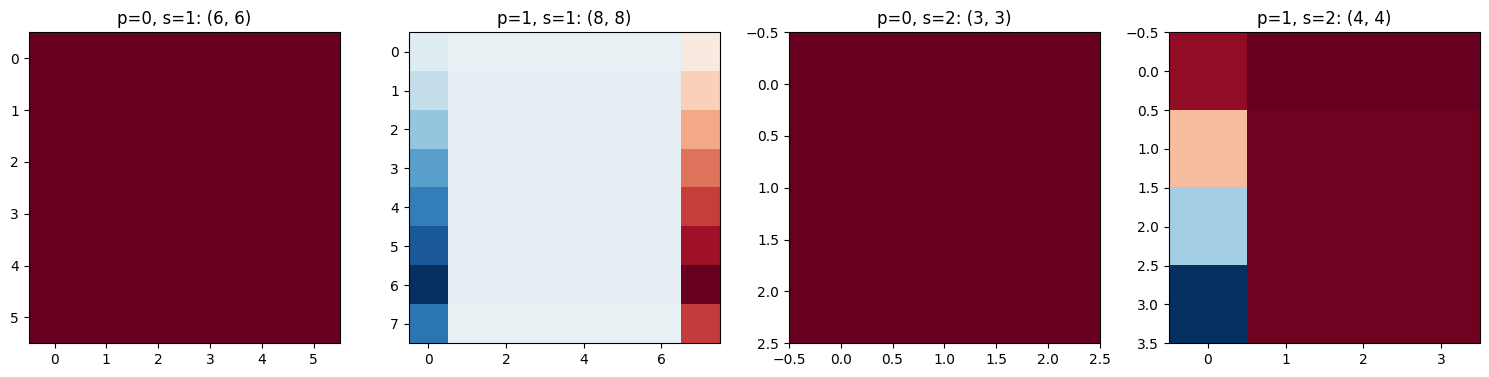

In [2]:
def convolution(image,kernel,stride=1,padding=0):
    if stride<1 or padding<0:raise ValueError('Неверные stride или padding')
    x=np.pad(np.asarray(image,dtype=float),padding)
    kh,kw=kernel.shape
    oh=(x.shape[0]-kh)//stride+1
    ow=(x.shape[1]-kw)//stride+1
    if min(oh,ow)<1:raise ValueError('Ядро больше изображения')
    result=np.zeros((oh,ow))
    for i in range(oh):
        for j in range(ow):result[i,j]=np.sum(x[i*stride:i*stride+kh,j*stride:j*stride+kw]*kernel)
    return result
fig,axes=plt.subplots(1,4,figsize=(15,4))
for ax,(p,s) in zip(axes,[(0,1),(1,1),(0,2),(1,2)]):
    result=convolution(image,kernel,s,p)
    print(f'padding={p}, stride={s}: {result.shape}')
    ax.imshow(result,cmap='RdBu');ax.set_title(f'p={p}, s={s}: {result.shape}')
plt.tight_layout();plt.show()
# Проверка на вручную вычисленном окне.
assert convolution(np.arange(1,10).reshape(3,3),np.ones((2,2)))[0,0]==12

## 3. Max и average pooling

Сравниваем выделение максимума и усреднение локальных активаций.

Исходная матрица 
 [[ 12.  20.  30.   0.]
 [  8.  12.   2.   0.]
 [ 34.  70.  37.   4.]
 [112. 100.  25.  12.]]
Max pooling 
 [[ 20.  30.]
 [112.  37.]]
Average pooling 
 [[13.   8. ]
 [79.  19.5]]


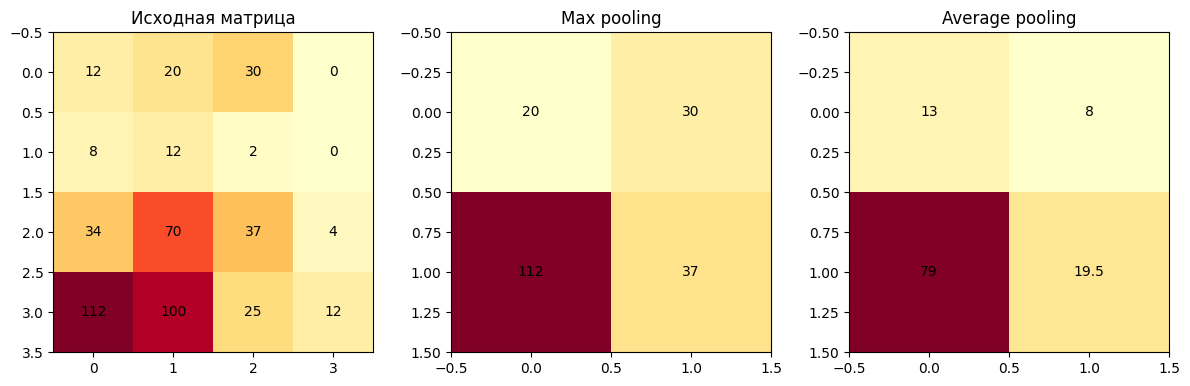

In [3]:
def pooling(x,size=2,stride=2,mode='max'):
    if mode not in ('max','avg'):raise ValueError(mode)
    reducer=np.max if mode=='max' else np.mean
    h=(x.shape[0]-size)//stride+1;w=(x.shape[1]-size)//stride+1
    return np.array([[reducer(x[i*stride:i*stride+size,j*stride:j*stride+size]) for j in range(w)] for i in range(h)])
x=np.array([[12,20,30,0],[8,12,2,0],[34,70,37,4],[112,100,25,12]],dtype=float)
fig,axes=plt.subplots(1,3,figsize=(12,4))
for ax,title,a in zip(axes,['Исходная матрица','Max pooling','Average pooling'],[x,pooling(x),pooling(x,mode='avg')]):
    print(title,'\n',a);ax.imshow(a,cmap='YlOrRd');ax.set_title(title)
    for (i,j),v in np.ndenumerate(a):ax.text(j,i,f'{v:g}',ha='center',va='center')
plt.tight_layout();plt.show()
assert np.array_equal(pooling(x),[[20,30],[112,37]])
assert np.allclose(pooling(x,mode='avg'),[[13,8],[79,19.5]])

## Вывод

Реализованы свёртка и два вида pooling. Padding=1 сохраняет размер для ядра 3×3 при stride=1, а stride=2 уменьшает разрешение. Max pooling сохраняет самые сильные отклики, average pooling сглаживает их: например, в нижнем левом окне получены 112 и 79 соответственно. Нулевое дополнение создаёт отдельные отклики на границе изображения.